# Notebook 2 - Làm sạch dữ liệu, pipeline và feature (Bước 4 - 5)

Notebook này đọc ba tập `train`, `val`, `test` do Notebook 1 tạo ra (đã được lọc chuẩn hóa kỳ hạn 36 tháng ở Bước 3.4, đủ 151 cột gốc) và làm tiếp:

4. Làm sạch dữ liệu và tạo **pipeline** học từ `train` rồi áp dụng sang `val`, `test`.
   - **Đồng nhất sản phẩm tín dụng:** Dữ liệu đã được chuẩn hóa 100% là các khoản vay **kỳ hạn 36 tháng** ngay từ Notebook 1, triệt tiêu hoàn toàn rủi ro lệch phân phối (Covariate Shift) do luật đáo hạn.
5. Chọn và lọc bỏ các cột không phù hợp (loại bỏ biến hằng số `term_months`, biến trùng lặp `grade` và `int_rate`), tạo feature mới và mã hóa hoàn chỉnh.

**Quy tắc:** mọi thứ *học một con số từ dữ liệu* (trung vị, độ lệch chuẩn, danh sách giá trị của biến phân loại, các ngưỡng) chỉ được tính trên `train`. `val` và `test` chỉ được *áp dụng*, không được dùng để học.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

In [2]:
SEED = 42
ROOT = Path("..")
DATA_DIR = ROOT / "data/processed"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.3f}".format)

In [3]:
train = pd.read_parquet(DATA_DIR / "train.parquet")
val = pd.read_parquet(DATA_DIR / "val.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")
data_dictionary = pd.read_csv(DATA_DIR / "data_dictionary.csv", index_col="column")

# Xác nhận cả 3 tập đều đã được lọc chỉ chứa kỳ hạn 36 tháng từ Notebook 01 (Mục 3.4)
assert (train["term_months"] == 36).all(), "Train chứa khoản vay khác 36 tháng!"
assert (val["term_months"] == 36).all(), "Val chứa khoản vay khác 36 tháng!"
assert (test["term_months"] == 36).all(), "Test chứa khoản vay khác 36 tháng!"
print(f"Tập dữ liệu đã chuẩn hóa 36 tháng từ Notebook 01: train={len(train):,}, val={len(val):,}, test={len(test):,}.")

Tập dữ liệu đã chuẩn hóa 36 tháng từ Notebook 01: train=408,188, val=92,631, test=88,669.


In [4]:
print("train:", train.shape, "| val:", val.shape, "| test:", test.shape)

train: (408188, 157) | val: (92631, 157) | test: (88669, 157)


In [5]:
assert train["issue_date"].max() < val["issue_date"].min()
assert val["issue_date"].max() < test["issue_date"].min()
print("Kiểm tra lại thứ tự thời gian: train < val < test.")

Kiểm tra lại thứ tự thời gian: train < val < test.


In [6]:
ALL_COLUMNS = list(data_dictionary.index)
print("Số cột gốc theo từ điển:", len(ALL_COLUMNS))
print("Các cột phụ do Notebook 1 thêm:", [c for c in train.columns if c not in ALL_COLUMNS])

Số cột gốc theo từ điển: 151
Các cột phụ do Notebook 1 thêm: ['default', 'issue_date', 'term_months', 'year', 'resolved', 'matured']


---
# Bước 4 - Làm sạch dữ liệu và tạo pipeline

**Tham khảo cách làm của người khác** (nêu tên và kỹ thuật theo tên/mô tả project; chưa đối chiếu nội dung gốc, mọi điều rút ra cho dữ liệu của ta đều do code bên dưới kiểm chứng):
- Tanish-Srivastava, `credit-risk-scorecard` - https://github.com/Tanish-Srivastava/credit-risk-scorecard : dùng danh sách cột được phép (whitelist) lúc nộp đơn.
- Arturo-GA, `lendingclub-default-risk` - https://github.com/Arturo-GA/lendingclub-default-risk : whitelist và kiểm tra tự động không để cột bị cấm lọt vào mô hình.
- vaibhavkev, `credit-risk` - https://github.com/vaibhavkev/credit-risk : whitelist cột và có test kiểm tra rò rỉ.

## 4.1 Tìm các giá trị bất thường trong dữ liệu
Ta chỉ **nhìn** các giá trị bất thường trên `train` để đặt ngưỡng. Hàm sau đếm số dòng vi phạm từng quy tắc logic.

In [7]:

def parse_month(series):
    return pd.to_datetime(series, format="%b-%Y")

In [8]:
def logic_checks(df):
    first_credit = parse_month(df["earliest_cr_line"])
    checks = {
        "annual_inc <= 0": df["annual_inc"] <= 0,
        "dti < 0": df["dti"] < 0,
        "dti > 100": df["dti"] > 100,
        "revol_util > 100": df["revol_util"] > 100,
        "fico_range_low > fico_range_high": df["fico_range_low"] > df["fico_range_high"],
        "tài khoản tín dụng đầu tiên mở sau ngày giải ngân": first_credit > df["issue_date"],
        "loan_amnt <= 0": df["loan_amnt"] <= 0,
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()})

**Bảng 1.** Số dòng vi phạm từng quy tắc logic, trên cả ba tập (chỉ dùng để quan sát).

In [9]:
checks_before = pd.DataFrame({"train": logic_checks(train), "val": logic_checks(val), "test": logic_checks(test)})
checks_before

,train,val,test
annual_inc <= 0,0,0,2
dti < 0,0,0,0
dti > 100,0,0,5
revol_util > 100,1321,421,461
fico_range_low > fico_range_high,0,0,0
tài khoản tín dụng đầu tiên mở sau ngày giải ngân,0,0,0
loan_amnt <= 0,0,0,0


In [10]:
rows_bad_only_later = [name for name, row in checks_before.iterrows() if row["train"] == 0 and (row["val"] + row["test"]) > 0]
print("Quy tắc không có dòng vi phạm nào ở train nhưng có ở val/test:", rows_bad_only_later)
print("Hành động -> các quy tắc này được đặt theo ý nghĩa của cột (dti là tỷ lệ phần trăm, thu nhập phải dương), "
      "không chỉnh theo val/test; ở đây ta chỉ nhìn số đếm để biết quy tắc có tác dụng hay không.")

Quy tắc không có dòng vi phạm nào ở train nhưng có ở val/test: ['annual_inc <= 0', 'dti > 100']
Hành động -> các quy tắc này được đặt theo ý nghĩa của cột (dti là tỷ lệ phần trăm, thu nhập phải dương), không chỉnh theo val/test; ở đây ta chỉ nhìn số đếm để biết quy tắc có tác dụng hay không.


In [11]:
print("Số id trùng lặp trong train:", train["id"].duplicated().sum(),
      "| trong val:", val["id"].duplicated().sum(), "| trong test:", test["id"].duplicated().sum())
print("Số id xuất hiện ở nhiều hơn một tập:", len(set(train["id"]) & set(val["id"])) + len(set(train["id"]) & set(test["id"])) + len(set(val["id"]) & set(test["id"])))

Số id trùng lặp trong train: 0 | trong val: 0 | trong test: 0


Số id xuất hiện ở nhiều hơn một tập: 0


Để đặt ngưỡng, ta xem phân phối ba cột hay có giá trị cực đoan, **chỉ trên train**.

**Bảng 2.** Phân vị của `dti`, `annual_inc`, `revol_util` trong train.

In [12]:
train[["dti", "annual_inc", "revol_util"]].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
dti,"408,188.000",17.488,8.072,0.000,0.370,2.050,16.990,36.230,39.580,39.990
annual_inc,"408,188.000","71,697.467","58,561.614","3,000.000","10,058.244","18,000.000","60,000.000","250,000.000","500,000.000","8,706,582.000"
revol_util,"407,976.000",55.185,23.361,0.000,0.000,3.100,56.000,97.900,102.400,892.300


In [13]:
n_dti_bad = ((train["dti"] < 0) | (train["dti"] > 100)).sum()
n_income_bad = (train["annual_inc"] <= 0).sum()
print(f"Số dòng train có dti ngoài khoảng 0-100: {n_dti_bad} ({n_dti_bad / len(train):.4%}).")
print(f"Số dòng train có annual_inc <= 0: {n_income_bad} ({n_income_bad / len(train):.4%}).")
print(f"revol_util: phân vị 99.9% là {train['revol_util'].quantile(0.999):.1f}, lớn nhất là {train['revol_util'].max():.1f}.")
print("Hành động -> dti là tỷ lệ phần trăm nên giá trị ngoài 0-100 coi là không hợp lệ; thu nhập <= 0 không hợp lệ; "
      "revol_util vượt 100 là có thể (dùng quá hạn mức) nên chỉ chặn trên ở phân vị 99.9% của train.")

Số dòng train có dti ngoài khoảng 0-100: 0 (0.0000%).
Số dòng train có annual_inc <= 0: 0 (0.0000%).
revol_util: phân vị 99.9% là 102.4, lớn nhất là 892.3.
Hành động -> dti là tỷ lệ phần trăm nên giá trị ngoài 0-100 coi là không hợp lệ; thu nhập <= 0 không hợp lệ; revol_util vượt 100 là có thể (dùng quá hạn mức) nên chỉ chặn trên ở phân vị 99.9% của train.


## 4.2 Các hàm làm sạch
Mỗi quy tắc là một quy tắc **cố định theo từng dòng** (cùng một quy tắc cho cả ba tập, không học gì từ `val` hay `test`). Hai ngưỡng được cố định từ `train`:

In [14]:
DTI_MAX = 100
REVOL_UTIL_CAP = round(float(train["revol_util"].quantile(0.999)), 1)
print("DTI_MAX =", DTI_MAX, "| REVOL_UTIL_CAP (phân vị 99.9% của train) =", REVOL_UTIL_CAP)

DTI_MAX = 100 | REVOL_UTIL_CAP (phân vị 99.9% của train) = 102.4


In [15]:
def fix_invalid_values(df):
        df = df.copy()
        
        # 1. Thu nhập phi lý (<= 0) -> gán NaN
        df.loc[df["annual_inc"] <= 0, "annual_inc"] = np.nan
        
        # 2. Khoản tiền vay phi lý (<= 0) -> gán NaN
        df.loc[df["loan_amnt"] <= 0, "loan_amnt"] = np.nan
        
        # 3. Tỷ lệ nợ/thu nhập DTI ngoài khoảng [0, 100] -> gán NaN
        df.loc[(df["dti"] < 0) | (df["dti"] > DTI_MAX), "dti"] = np.nan
        
        # 4. Tỷ lệ dùng thẻ tín dụng: cắt trần ở 102%
        df["revol_util"] = df["revol_util"].clip(upper=REVOL_UTIL_CAP)
        
        # 5. Điểm FICO nghịch lý (cận dưới lớn hơn cận trên) -> gán NaN cả 2 cột
        bad_fico = df["fico_range_low"] > df["fico_range_high"]
        df.loc[bad_fico, ["fico_range_low", "fico_range_high"]] = np.nan
        
        # 6. Tài khoản tín dụng mở sau ngày vay -> gán NaN để không tính ra số năm âm
        if "earliest_cr_line" in df.columns and "issue_date" in df.columns:
            first_credit = parse_month(df["earliest_cr_line"])
            bad_credit_date = first_credit > df["issue_date"]
            df.loc[bad_credit_date, "earliest_cr_line"] = np.nan
            
        return df


In [16]:
def drop_duplicate_ids(df):
    return df.drop_duplicates(subset="id")

In [17]:
train_c = drop_duplicate_ids(fix_invalid_values(train))
val_c = drop_duplicate_ids(fix_invalid_values(val))
test_c = drop_duplicate_ids(fix_invalid_values(test))
print("Số dòng sau làm sạch - train:", len(train_c), "| val:", len(val_c), "| test:", len(test_c))

Số dòng sau làm sạch - train: 408188 | val: 92631 | test: 88669


**Bảng 3.** Chạy lại các quy tắc logic sau khi làm sạch (các quy tắc đã sửa phải về 0 ở cả ba tập).

In [18]:
checks_after = pd.DataFrame({"train": logic_checks(train_c), "val": logic_checks(val_c), "test": logic_checks(test_c)})
checks_after

,train,val,test
annual_inc <= 0,0,0,0
dti < 0,0,0,0
dti > 100,0,0,0
revol_util > 100,1321,421,461
fico_range_low > fico_range_high,0,0,0
tài khoản tín dụng đầu tiên mở sau ngày giải ngân,0,0,0
loan_amnt <= 0,0,0,0


In [19]:
fixed_rules = ["annual_inc <= 0", "dti < 0", "dti > 100"]
assert (checks_after.loc[fixed_rules] == 0).all().all()
print("Các quy tắc đã sửa đều về 0 ở cả ba tập.")
still = checks_after[(checks_after > 0).any(axis=1)]
print("Quy tắc còn dòng vi phạm (không sửa vì là giá trị có thể xảy ra hoặc không bất thường):", still.index.tolist())

Các quy tắc đã sửa đều về 0 ở cả ba tập.
Quy tắc còn dòng vi phạm (không sửa vì là giá trị có thể xảy ra hoặc không bất thường): ['revol_util > 100']


## 4.3 Giá trị thiếu
**Bảng 4.** 25 cột có tỷ lệ thiếu cao nhất trong `train`, cùng tỷ lệ thiếu ở `val` và `test` để thấy dữ liệu thiếu có ổn định theo thời gian không.

In [20]:
missing_table = pd.DataFrame({
    "train_%": train_c[ALL_COLUMNS].isna().mean() * 100,
    "val_%": val_c[ALL_COLUMNS].isna().mean() * 100,
    "test_%": test_c[ALL_COLUMNS].isna().mean() * 100,
})
missing_table.sort_values("train_%", ascending=False).head(25)

,train_%,val_%,test_%
member_id,100.000,100.000,100.000
sec_app_num_rev_accts,100.000,100.000,100.000
sec_app_open_act_il,100.000,100.000,100.000
sec_app_inq_last_6mths,100.000,100.000,100.000
sec_app_open_acc,100.000,100.000,100.000
dti_joint,100.000,100.000,99.732
open_rv_24m,100.000,100.000,83.214
total_cu_tl,100.000,100.000,83.214
annual_inc_joint,100.000,100.000,99.730
verification_status_joint,100.000,100.000,99.730


In [21]:
n_all_empty = (missing_table["train_%"] == 100).sum()
n_some = ((missing_table["train_%"] > 0) & (missing_table["train_%"] < 100)).sum()
shift = (missing_table["test_%"] - missing_table["train_%"]).abs().sort_values(ascending=False)
print(f"Cột trống hoàn toàn trong train: {n_all_empty}. Cột thiếu một phần: {n_some}. Cột không thiếu: {(missing_table['train_%'] == 0).sum()}.")
print(f"Cột có tỷ lệ thiếu thay đổi nhiều nhất giữa train và test: {shift.index[0]} (lệch {shift.iloc[0]:.1f} điểm %).")
print("Hành động -> việc bỏ cột thiếu nhiều sẽ được quyết định ở Bước 5 bằng ngưỡng tính trên train; "
      "việc điền giá trị thiếu (cần học trung vị) nằm trong pipeline ở mục 4.4.")

Cột trống hoàn toàn trong train: 32. Cột thiếu một phần: 66. Cột không thiếu: 53.
Cột có tỷ lệ thiếu thay đổi nhiều nhất giữa train và test: desc (lệch 18.4 điểm %).
Hành động -> việc bỏ cột thiếu nhiều sẽ được quyết định ở Bước 5 bằng ngưỡng tính trên train; việc điền giá trị thiếu (cần học trung vị) nằm trong pipeline ở mục 4.4.


---
# Bước 5 - Chọn, lọc bỏ feature và feature engineering

File gốc có 151 cột nhưng phần lớn không dùng được. Ta gán **mỗi cột vào đúng một nhóm** theo thứ tự các câu hỏi sau, và mỗi nhóm có bằng chứng do code tính trên `train`:

1. Cột nhãn và cột phụ trợ?
2. Cột định danh (mỗi khoản vay một giá trị riêng)?
3. Cột chỉ có sau khi khoản vay đã bắt đầu (rò rỉ thông tin - *leakage*) hoặc không rõ thời điểm?
4. Cột của hồ sơ vay chung?
5. Cột chữ có quá nhiều giá trị khác nhau?
6. Cột (gần như) hằng số?
7. Cột thiếu quá nhiều trong `train`?
8. Còn lại: **cột ứng viên** để giữ.

**Tham khảo cách làm của người khác** (theo tên/mô tả project, chưa đối chiếu nội dung gốc):
- Arnav618, `lending-club-credit-risk` - https://github.com/Arnav618/lending-club-credit-risk : phát hiện leakage bằng thước đo thông tin tương hỗ (mutual information) rồi loại cột; ta dùng ROC-AUC từng cột đơn giản hơn nhưng cùng ý tưởng.
- yanxiali, `Predicting-Default-Clients` - https://github.com/yanxiali/Predicting-Default-Clients-of-Lending-Club-Loans : lọc biến bằng tương quan Pearson.

## 5.1 Hồ sơ của từng cột trên train
Hàm sau tính, cho mỗi cột gốc, các con số dùng để phân nhóm: là cột chữ hay số, tỷ lệ thiếu, số giá trị khác nhau, tỷ lệ giá trị phổ biến nhất.

In [22]:
def profile_columns(df, columns):
    rows = {}
    for col in columns:
        s = df[col]
        top_share = s.value_counts(normalize=True, dropna=True).iloc[0] if s.notna().any() else np.nan
        rows[col] = {
            "is_text": not pd.api.types.is_numeric_dtype(s),
            "missing_share": s.isna().mean(),
            "n_unique": s.nunique(),
            "unique_share": s.nunique() / max(s.notna().sum(), 1),
            "top_value_share": top_share,
        }
    return pd.DataFrame(rows).T

In [23]:
profile = profile_columns(train_c, ALL_COLUMNS)
profile = profile.astype({"is_text": bool, "missing_share": float, "n_unique": int, "unique_share": float, "top_value_share": float})
print("Đã tính hồ sơ cho", len(profile), "cột.")

Đã tính hồ sơ cho 151 cột.


## 5.2 Cột định danh
Một cột định danh có gần như mỗi dòng một giá trị riêng, nên không mang thông tin để dự đoán.

**Bảng 5.** Các cột có tỷ lệ giá trị khác nhau trên 90% hoặc trống hoàn toàn.

In [24]:
identifier_view = profile[(profile["unique_share"] > 0.9) & (profile["missing_share"] < 0.5)]
identifier_view[["is_text", "missing_share", "n_unique", "unique_share"]]

,is_text,missing_share,n_unique,unique_share
id,True,0.000,408188,1.000
url,True,0.000,408188,1.000
total_pymnt,False,0.000,385700,0.945


In [25]:
UNIQUE_SHARE_ID = 0.99
identifier_cols = profile.index[(profile["unique_share"] >= UNIQUE_SHARE_ID) & (profile["missing_share"] < 0.5)].tolist()
print(f"Cột định danh (từ {UNIQUE_SHARE_ID:.0%} giá trị khác nhau và thiếu dưới 50%):", identifier_cols)
print("Quyết định -> loại bỏ các cột định danh.")

Cột định danh (từ 99% giá trị khác nhau và thiếu dưới 50%): ['id', 'url']
Quyết định -> loại bỏ các cột định danh.


Có những cột **trống hoàn toàn trong train**. Ta xem chúng có dữ liệu ở `val` / `test` hay không, để hiểu vì sao chúng trống.

In [26]:
empty_cols = profile.index[profile["missing_share"] == 1].tolist()
has_data_later = [c for c in empty_cols if val_c[c].notna().any() or test_c[c].notna().any()]
print(f"Số cột trống hoàn toàn trong train: {len(empty_cols)}")
print(f"Trong đó có dữ liệu ở val hoặc test (tức là chỉ bắt đầu được ghi muộn hơn thời gian train): {len(has_data_later)}")
print("Các cột đó:", has_data_later)

Số cột trống hoàn toàn trong train: 32
Trong đó có dữ liệu ở val hoặc test (tức là chỉ bắt đầu được ghi muộn hơn thời gian train): 17
Các cột đó: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']


In [27]:
print("Quyết định -> mô hình không thể học gì từ một cột trống trong train, nên loại bỏ toàn bộ các cột trống hoàn toàn trong train.")

Quyết định -> mô hình không thể học gì từ một cột trống trong train, nên loại bỏ toàn bộ các cột trống hoàn toàn trong train.


## 5.3 Cột chỉ có sau khi vay, hoặc không rõ thời điểm (leakage)
Mô hình sẽ dùng để duyệt khoản vay **trước khi** cho vay, nên mọi cột chỉ xuất hiện sau khi khoản vay bắt đầu đều không được dùng. Từ điển ở Notebook 1 đã gán giả thuyết cho từng cột. Giờ ta **kiểm chứng bằng code**.

Với mỗi cột bị nghi, ta đo xem *một mình cột đó* dự đoán nhãn tốt đến đâu bằng ROC-AUC trên train (0,5 là vô dụng, 1,0 là hoàn hảo; ta lấy `max(AUC, 1-AUC)` để không phụ thuộc chiều). Cách đo cho cột chữ: nếu có tối đa 100 giá trị khác nhau, ta thay mỗi giá trị bằng tỷ lệ vỡ nợ của giá trị đó trong train (một phép đo chẩn đoán trên chính train nên hơi lạc quan); nếu có nhiều giá trị hơn, ta chỉ xét chỉ báo "có giá trị hay không".

In [28]:
def single_column_auc(df, column):
    series = df[column]
    if pd.api.types.is_numeric_dtype(series):
        values = series.fillna(series.median())
    elif series.nunique() <= 100:
        # cột chữ ít giá trị: thay mỗi giá trị bằng tỷ lệ vỡ nợ của giá trị đó trong chính tập này (chỉ để chẩn đoán)
        values = df.groupby(series.fillna("(thiếu)"))["default"].transform("mean")
    else:
        values = series.notna().astype(int)        # cột chữ nhiều giá trị: chỉ xét "có giá trị hay không"
    if values.nunique() < 2:
        return 0.5
    auc = roc_auc_score(df["default"], values)
    return max(auc, 1 - auc)

In [29]:
META_COLUMNS = ["default", "loan_status", "issue_d", "issue_date", "year", "resolved", "matured"]

# 1. Lấy Series với index là tên cột
if "column" in data_dictionary.columns:
    timing = data_dictionary.set_index("column")["known_at_application"]
else:
    timing = data_dictionary["known_at_application"]

# 2. Phòng ngừa trường hợp chưa chạy các cell trước
if "identifier_cols" not in locals():
    identifier_cols = profile.index[(profile["unique_share"] >= 0.99) & (profile["missing_share"] < 0.5)].tolist() if "profile" in locals() else ["id", "url"]
if "empty_cols" not in locals():
    empty_cols = profile.index[profile["missing_share"] == 1].tolist() if "profile" in locals() else []

# 3. Tập hợp các cột cần bỏ qua
skip = set(META_COLUMNS) | set(identifier_cols) | set(empty_cols)

# 4. Lọc cột rò rỉ (No / Uncertain) và cột lúc nộp đơn (Yes)
suspect_columns = [c for c in timing.index if timing.get(c) in ("No", "Uncertain") and c not in skip]
application_columns = [c for c in timing.index if timing.get(c) == "Yes" and c not in skip]

print("Số cột nghi là sau khi vay hoặc không rõ:", len(suspect_columns), "| số cột giả thuyết là biết lúc nộp đơn:", len(application_columns))

Số cột nghi là sau khi vay hoặc không rõ: 42 | số cột giả thuyết là biết lúc nộp đơn: 73


Với các cột **không rõ thời điểm** (giả thuyết "Không rõ"), ta xem thêm dữ liệu của chính chúng.

**Bảng 7.** Các cột "Không rõ": tỷ lệ giá trị phổ biến nhất, số giá trị khác nhau và AUC đơn cột.

In [30]:
uncertain = [c for c in suspect_columns if timing[c] == "Uncertain"]
uncertain_table = profile.loc[uncertain, ["missing_share", "n_unique", "top_value_share"]].copy()
uncertain_table["ý nghĩa"] = data_dictionary.loc[uncertain, "meaning"]
uncertain_table

,missing_share,n_unique,top_value_share,ý nghĩa
funded_amnt,0.000,1320,0.082,Số tiền được duyệt/giải ngân cho khoản vay (USD)
funded_amnt_inv,0.000,1601,0.075,Số tiền do nhà đầu tư cấp cho khoản vay (USD)
pymnt_plan,0.000,1,1.000,Cờ cho biết khoản vay có kế hoạch trả nợ riêng hay không
initial_list_status,0.000,2,0.620,Trạng thái niêm yết ban đầu của khoản vay (w hoặc f)
policy_code,0.000,1,1.000,Mã chính sách: sản phẩm công khai hay không công khai
disbursement_method,0.000,1,1.000,Cách giải ngân: tiền mặt hay trả thẳng cho chủ nợ khác


In [31]:
same_as_request = (train_c["funded_amnt"] == train_c["loan_amnt"]).mean()
print(f"funded_amnt bằng đúng loan_amnt ở {same_as_request:.1%} số khoản vay trong train: gần như trùng với số tiền người vay xin, nên không thêm thông tin.")
print("Quyết định -> với cột không rõ thời điểm ta chọn an toàn: loại bỏ, để tránh vô tình dùng thông tin biết sau khi cho vay.")

funded_amnt bằng đúng loan_amnt ở 100.0% số khoản vay trong train: gần như trùng với số tiền người vay xin, nên không thêm thông tin.
Quyết định -> với cột không rõ thời điểm ta chọn an toàn: loại bỏ, để tránh vô tình dùng thông tin biết sau khi cho vay.


## 5.4 Cột của hồ sơ vay chung
Các cột `*_joint` và `sec_app_*` chỉ có giá trị khi hồ sơ là vay chung. **Bảng 8.** Tỷ lệ thiếu của các cột này theo `application_type` (trên train).

In [32]:
joint_columns = [c for c in ALL_COLUMNS if c.endswith("_joint") or c.startswith("sec_app_")]
missing_by_type = train_c.groupby("application_type")[joint_columns].apply(lambda g: g.isna().mean()).T * 100
missing_by_type.columns = [f"thiếu % ({c})" for c in missing_by_type.columns]
missing_by_type

,thiếu % (Individual)
annual_inc_joint,100.000
dti_joint,100.000
verification_status_joint,100.000
revol_bal_joint,100.000
sec_app_fico_range_low,100.000
sec_app_fico_range_high,100.000
sec_app_earliest_cr_line,100.000
sec_app_inq_last_6mths,100.000
sec_app_mort_acc,100.000
sec_app_open_acc,100.000


In [33]:
type_share = train_c["application_type"].value_counts(normalize=True)
print("Tỷ lệ theo application_type trong train:", {k: f"{v:.1%}" for k, v in type_share.items()})
print("Tỷ lệ theo application_type trong test:", {k: f"{v:.1%}" for k, v in test_c["application_type"].value_counts(normalize=True).items()})
print(f"Số cột hồ sơ vay chung: {len(joint_columns)}; tỷ lệ thiếu trung bình toàn train: {train_c[joint_columns].isna().mean().mean():.1%}.")
if len(type_share) == 1:
    print(f"Trong train chỉ có một loại hồ sơ ({type_share.index[0]}), nên các cột vay chung không có dữ liệu để học và application_type cũng là hằng số.")
print("Quyết định -> loại bỏ các cột hồ sơ vay chung.")

Tỷ lệ theo application_type trong train: {'Individual': '100.0%'}
Tỷ lệ theo application_type trong test: {'Individual': '99.7%', 'Joint App': '0.3%'}
Số cột hồ sơ vay chung: 16; tỷ lệ thiếu trung bình toàn train: 100.0%.
Trong train chỉ có một loại hồ sơ (Individual), nên các cột vay chung không có dữ liệu để học và application_type cũng là hằng số.
Quyết định -> loại bỏ các cột hồ sơ vay chung.


## 5.5 Cột chữ có quá nhiều giá trị khác nhau
Cột chữ có hàng trăm giá trị (tên công việc, mô tả tự do...) không dùng trực tiếp được, trừ khi là ngày tháng sẽ đổi thành số. Ta tìm ngưỡng từ phân phối số giá trị khác nhau của các cột chữ.

**Bảng 9.** Các cột chữ sắp theo số giá trị khác nhau trong train.

In [34]:
text_profile = profile[profile["is_text"]].sort_values("n_unique", ascending=False)
text_profile[["n_unique", "missing_share"]].assign(ý_nghĩa=data_dictionary.loc[text_profile.index, "meaning"]).head(20)

,n_unique,missing_share,ý_nghĩa
id,408188,0.000,Mã khoản vay do Lending Club gán
url,408188,0.000,Đường dẫn tới trang của khoản vay trên website Lending Club
emp_title,166034,0.066,Chức danh công việc do người vay nhập
desc,74261,0.816,Mô tả khoản vay do người vay viết
title,37586,0.000,Tiêu đề khoản vay do người vay viết
zip_code,878,0.000,3 chữ số đầu của mã bưu chính người vay
earliest_cr_line,666,0.000,Tháng mở tài khoản tín dụng đầu tiên
last_credit_pull_d,87,0.000,Tháng Lending Club kéo hồ sơ tín dụng lần gần nhất
last_pymnt_d,84,0.001,Tháng nhận được khoản thanh toán gần nhất
settlement_date,74,0.987,Ngày đạt thỏa thuận tất toán nợ


In [35]:
def is_month_date(series, sample=2000):
    values = series.dropna().head(sample)
    if values.empty:
        return False
    return pd.to_datetime(values, format="%b-%Y", errors="coerce").notna().mean() > 0.99

In [36]:
text_columns = profile.index[profile["is_text"]]
date_like = [c for c in text_columns if is_month_date(train_c[c])]
print("Cột chữ có dạng ngày tháng (vd 'Dec-2015'):", date_like)

Cột chữ có dạng ngày tháng (vd 'Dec-2015'): ['issue_d', 'earliest_cr_line', 'last_pymnt_d', 'last_credit_pull_d', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'debt_settlement_flag_date', 'settlement_date']


In [37]:
MAX_UNIQUE_CATEGORY = 100
many_values = [c for c in text_columns if profile.loc[c, "n_unique"] > MAX_UNIQUE_CATEGORY and c not in date_like]
print(f"Cột chữ (không phải ngày) có hơn {MAX_UNIQUE_CATEGORY} giá trị khác nhau:", many_values)
few_values = profile.loc[[c for c in text_columns if c not in date_like and c not in many_values], "n_unique"].sort_values()
print("Số giá trị khác nhau lớn nhất của các cột chữ còn lại:", few_values.index[-1], int(few_values.iloc[-1]))
print("Quyết định -> loại các cột nhiều giá trị (one-hot sẽ tạo quá nhiều cột); giữ cột ngày để đổi sang số ở mục 5.9.")

Cột chữ (không phải ngày) có hơn 100 giá trị khác nhau: ['id', 'emp_title', 'url', 'desc', 'title', 'zip_code']
Số giá trị khác nhau lớn nhất của các cột chữ còn lại: addr_state 50
Quyết định -> loại các cột nhiều giá trị (one-hot sẽ tạo quá nhiều cột); giữ cột ngày để đổi sang số ở mục 5.9.


## 5.6 Cột (gần như) hằng số
Cột mà một giá trị chiếm gần hết các dòng gần như không giúp phân biệt khoản vay.

**Bảng 10.** Các cột có giá trị phổ biến nhất chiếm từ 95% trở lên (trên train).

In [38]:
near_constant_view = profile[profile["top_value_share"] >= 0.95][["top_value_share", "missing_share", "n_unique"]]
near_constant_view = near_constant_view.assign(ý_nghĩa=data_dictionary.loc[near_constant_view.index, "meaning"])
near_constant_view.sort_values("top_value_share", ascending=False)

,top_value_share,missing_share,n_unique,ý_nghĩa
term,1.000,0.000,1,Kỳ hạn vay: 36 hoặc 60 tháng
pymnt_plan,1.000,0.000,1,Cờ cho biết khoản vay có kế hoạch trả nợ riêng hay không
out_prncp,1.000,0.000,1,Số tiền gốc còn nợ (USD)
out_prncp_inv,1.000,0.000,1,Số tiền gốc còn nợ phần do nhà đầu tư cấp (USD)
application_type,1.000,0.000,1,Hồ sơ vay cá nhân (Individual) hay vay chung (Joint App)
policy_code,1.000,0.000,1,Mã chính sách: sản phẩm công khai hay không công khai
hardship_flag,1.000,0.000,1,Cờ cho biết người vay có kế hoạch hỗ trợ khó khăn tài chính hay không
disbursement_method,1.000,0.000,1,Cách giải ngân: tiền mặt hay trả thẳng cho chủ nợ khác
deferral_term,1.000,0.999,1,Số tháng được hoãn trả theo kế hoạch hỗ trợ
hardship_length,1.000,0.999,1,Số tháng của kế hoạch hỗ trợ


In [39]:
TOP_SHARE_CONSTANT = 0.99
constant_columns = profile.index[profile["top_value_share"] >= TOP_SHARE_CONSTANT].tolist()
print(f"Số cột có một giá trị chiếm từ {TOP_SHARE_CONSTANT:.0%} dòng trở lên: {len(constant_columns)}")
borderline = profile[(profile["top_value_share"] >= 0.95) & (profile["top_value_share"] < TOP_SHARE_CONSTANT)]
print("Cột sát ngưỡng (95%-99%), được giữ lại:", borderline.index.tolist())

Số cột có một giá trị chiếm từ 99% dòng trở lên: 16
Cột sát ngưỡng (95%-99%), được giữ lại: ['total_rec_late_fee', 'collections_12_mths_ex_med', 'tax_liens', 'debt_settlement_flag']


## 5.7 Cột thiếu quá nhiều trong train
Ngưỡng thiếu được tính **chỉ trên train**. Để chọn ngưỡng hợp lý, ta xem phân phối tỷ lệ thiếu của các cột còn lại và năm đầu tiên mỗi cột có dữ liệu.

**Bảng 11.** Số cột theo khoảng tỷ lệ thiếu trong train.

In [40]:
missing_bins = pd.cut(profile["missing_share"], [-0.001, 0, 0.05, 0.10, 0.30, 0.60, 0.90, 1.0],
                      labels=["0%", "0-5%", "5-10%", "10-30%", "30-60%", "60-90%", "90-100%"])
missing_bins.value_counts().sort_index().to_frame("số cột")

,số cột
missing_share,
0%,53
0-5%,14
5-10%,25
10-30%,1
30-60%,1
60-90%,5
90-100%,52


In [41]:
MAX_MISSING = 0.30
too_empty = profile.index[profile["missing_share"] > MAX_MISSING].tolist()
mid_missing = profile[(profile["missing_share"] > 0.05) & (profile["missing_share"] <= MAX_MISSING)]
print(f"Số cột thiếu trên {MAX_MISSING:.0%} trong train: {len(too_empty)}")
print(f"Số cột thiếu từ 5% đến {MAX_MISSING:.0%} (được giữ và điền trung vị): {len(mid_missing)}")

Số cột thiếu trên 30% trong train: 58
Số cột thiếu từ 5% đến 30% (được giữ và điền trung vị): 26


In [42]:
first_year_train = {c: train_c.loc[train_c[c].notna(), "year"].min() for c in mid_missing.index}
print("Năm đầu tiên có dữ liệu của các cột thiếu 5%-30% (trong train):")
print(pd.Series(first_year_train).astype(int).value_counts().sort_index().to_string())
print("Lưu ý -> các cột này thiếu vì được Lending Club bắt đầu ghi từ năm đó; điền trung vị cho các khoản vay trước đó là một giả định đơn giản, "
      "ghi lại như một hạn chế.")

Năm đầu tiên có dữ liệu của các cột thiếu 5%-30% (trong train):
2012    26
Lưu ý -> các cột này thiếu vì được Lending Club bắt đầu ghi từ năm đó; điền trung vị cho các khoản vay trước đó là một giả định đơn giản, ghi lại như một hạn chế.


## 5.8 Gán mỗi cột vào đúng một nhóm
Hàm `classify_column` đi qua các câu hỏi theo đúng thứ tự ở đầu bước 5 và trả về nhóm của cột ngay khi gặp câu trả lời "có" đầu tiên. Vì dùng thứ tự cố định nên mỗi cột chỉ rơi vào một nhóm.

In [43]:
def classify_column(column):
    p = profile.loc[column] if column in profile.index else None
    if column in META_COLUMNS or p is None:
        return "nhãn / cột phụ trợ"
    if column in identifier_cols:
        return "định danh"
    if column in empty_cols:
        return "trống hoàn toàn trong train"
    if timing.get(column) in ("No", "Uncertain"):
        return "sau khi vay / không rõ thời điểm"
    if column in joint_columns:
        return "hồ sơ vay chung"
    if column in many_values:
        return "chữ có quá nhiều giá trị"
    if p["top_value_share"] >= TOP_SHARE_CONSTANT:
        return "(gần như) hằng số"
    if p["missing_share"] > MAX_MISSING:
        return "thiếu quá nhiều trong train"
    return "giữ lại làm ứng viên"

In [44]:
column_group = pd.Series({c: classify_column(c) for c in ALL_COLUMNS}, name="nhóm")
print("Đã phân nhóm", len(column_group), "cột.")

Đã phân nhóm 151 cột.


In [45]:
assert len(column_group) == len(ALL_COLUMNS) == 151
assert set(column_group.index) == set(ALL_COLUMNS)
assert column_group.notna().all()
print("Kiểm tra qua: cả 151 cột đều được gán đúng một nhóm, không sót cột nào.")

Kiểm tra qua: cả 151 cột đều được gán đúng một nhóm, không sót cột nào.


**Bảng 12.** Số cột trong từng nhóm.

In [46]:
group_summary = column_group.value_counts().to_frame("số cột")
group_summary.loc["Tổng"] = group_summary["số cột"].sum()
group_summary

,số cột
nhóm,
giữ lại làm ứng viên,57
sau khi vay / không rõ thời điểm,42
trống hoàn toàn trong train,32
(gần như) hằng số,7
thiếu quá nhiều trong train,5
chữ có quá nhiều giá trị,4
định danh,2
nhãn / cột phụ trợ,2
Tổng,151


**Bảng 12b.** Danh sách cột trong từng nhóm (trừ nhóm giữ lại, xem Bảng 13).

In [47]:
for group_name, members in column_group.groupby(column_group).groups.items():
    if group_name != "giữ lại làm ứng viên":
        print(f"[{group_name}] ({len(members)} cột):", ", ".join(members))

[(gần như) hằng số] (7 cột): term, application_type, acc_now_delinq, chargeoff_within_12_mths, delinq_amnt, num_tl_120dpd_2m, num_tl_30dpd
[chữ có quá nhiều giá trị] (4 cột): emp_title, desc, title, zip_code
[nhãn / cột phụ trợ] (2 cột): issue_d, loan_status
[sau khi vay / không rõ thời điểm] (42 cột): funded_amnt, funded_amnt_inv, pymnt_plan, initial_list_status, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int, total_rec_late_fee, recoveries, collection_recovery_fee, last_pymnt_d, last_pymnt_amnt, last_credit_pull_d, last_fico_range_high, last_fico_range_low, policy_code, hardship_flag, hardship_type, hardship_reason, hardship_status, deferral_term, hardship_amount, hardship_start_date, hardship_end_date, payment_plan_start_date, hardship_length, hardship_dpd, hardship_loan_status, orig_projected_additional_accrued_interest, hardship_payoff_balance_amount, hardship_last_payment_amount, disbursement_method, debt_settlement_flag, debt_settlement_fl

In [48]:
kept_candidates = column_group[column_group == "giữ lại làm ứng viên"].index.tolist()
print(f"{len(ALL_COLUMNS)} cột gốc -> {len(kept_candidates)} cột ứng viên được giữ lại ({len(kept_candidates) / len(ALL_COLUMNS):.0%}).")

151 cột gốc -> 57 cột ứng viên được giữ lại (38%).


**Bảng 13.** Các cột ứng viên được giữ lại, kèm ý nghĩa và kiểu dữ liệu.

In [49]:
kept_table = data_dictionary.loc[kept_candidates, ["meaning"]].assign(
    kiểu=["chữ" if profile.loc[c, "is_text"] else "số" for c in kept_candidates],
    thiếu_pct=profile.loc[kept_candidates, "missing_share"] * 100)
kept_table

,meaning,kiểu,thiếu_pct
column,,,
loan_amnt,Số tiền người vay đề nghị vay (USD),số,0.000
int_rate,Lãi suất của khoản vay (%/năm),số,0.000
installment,Số tiền trả góp mỗi tháng (USD),số,0.000
grade,Hạng rủi ro A-G do Lending Club gán,chữ,0.000
sub_grade,Hạng rủi ro chi tiết A1-G5 do Lending Club gán,chữ,0.000
emp_length,Số năm làm việc ở công việc hiện tại (dưới 1 năm đến 10+ năm),chữ,5.576
home_ownership,"Tình trạng nhà ở: thuê, thế chấp, sở hữu,...",chữ,0.000
annual_inc,Thu nhập hằng năm do người vay tự khai (USD),số,0.000
verification_status,Thu nhập đã được Lending Club xác minh hay chưa,chữ,0.000


In [50]:
dropped_leak = column_group[column_group == "sau khi vay / không rõ thời điểm"].index
used_by_name = [c for c in dropped_leak if c in kept_candidates]
assert not used_by_name
print("Kiểm tra qua: không cột nào thuộc nhóm 'sau khi vay / không rõ thời điểm' nằm trong danh sách giữ lại.")

Kiểm tra qua: không cột nào thuộc nhóm 'sau khi vay / không rõ thời điểm' nằm trong danh sách giữ lại.


## 5.9 Feature engineering
Từ các cột ứng viên, ta tạo thêm feature dễ dùng hơn. Mỗi feature là **một hàm riêng**, là công thức cố định theo từng dòng (không học gì từ dữ liệu), nên áp dụng cho cả ba tập được.

| Feature mới | Công thức | Lý do |
|---|---|---|
| `term_months` | chữ `" 36 months"` -> số 36 | Mô hình cần số |
| `emp_length_years` | `"< 1 year"` -> 0, `"10+ years"` -> 10 | Mô hình cần số |
| `fico_avg` | trung bình `fico_range_low` và `fico_range_high` | Hai cột này gần như cùng một thông tin |
| `credit_history_years` | (ngày giải ngân - ngày mở tài khoản đầu tiên) / 365.25 | Lịch sử tín dụng dài hay ngắn |
| `loan_to_income` | `loan_amnt / annual_inc` | Khoản vay lớn so với thu nhập |
| `log_annual_inc`, `log_revol_bal` | log(1 + x) | Thu nhập và dư nợ lệch phải mạnh |

In [51]:
def make_term_months(df):
    return df["term"].str.extract(r"(\d+)")[0].astype(float)

In [52]:
def make_emp_length_years(df):
    text = df["emp_length"].replace({"< 1 year": "0 years"})
    return text.str.extract(r"(\d+)")[0].astype(float)

In [53]:
def make_fico_avg(df):
    return (df["fico_range_low"] + df["fico_range_high"]) / 2

In [54]:
def make_credit_history_years(df):
    first_credit = parse_month(df["earliest_cr_line"])
    return (df["issue_date"] - first_credit).dt.days / 365.25

Tỷ lệ `loan_to_income` có thể rất lớn nếu thu nhập khai quá nhỏ. Ta chặn trên bằng phân vị 99.9% của **train** (một con số cố định học từ train, áp dụng như nhau cho cả ba tập).

In [55]:
ratio_train = train_c["loan_amnt"] / train_c["annual_inc"]
LOAN_TO_INCOME_CAP = round(float(ratio_train.quantile(0.999)), 3)
print("LOAN_TO_INCOME_CAP (phân vị 99.9% của train) =", LOAN_TO_INCOME_CAP, "| giá trị lớn nhất trong train:", round(float(ratio_train.max()), 3))

LOAN_TO_INCOME_CAP (phân vị 99.9% của train) = 0.5 | giá trị lớn nhất trong train: 0.713


In [56]:
def make_loan_to_income(df):
    return (df["loan_amnt"] / df["annual_inc"]).clip(upper=LOAN_TO_INCOME_CAP)

In [57]:
def make_log_annual_inc(df):
    return np.log1p(df["annual_inc"])

In [58]:
def make_log_revol_bal(df):
    return np.log1p(df["revol_bal"])

Hàm `add_features` ghép tất cả các hàm trên và thêm vào bảng dữ liệu.

In [59]:
def add_features(df):
    df = df.copy()
    df["emp_length_years"] = make_emp_length_years(df)
    df["fico_avg"] = make_fico_avg(df)
    df["credit_history_years"] = make_credit_history_years(df)
    df["loan_to_income"] = make_loan_to_income(df)
    df["log_annual_inc"] = make_log_annual_inc(df)
    df["log_revol_bal"] = make_log_revol_bal(df)
    return df


In [60]:
NEW_FEATURES = ["emp_length_years", "fico_avg", "credit_history_years",
                "loan_to_income", "log_annual_inc", "log_revol_bal"]
print("Danh sách feature mới:", NEW_FEATURES)


Danh sách feature mới: ['emp_length_years', 'fico_avg', 'credit_history_years', 'loan_to_income', 'log_annual_inc', 'log_revol_bal']


In [61]:
needed_raw = ["emp_length", "earliest_cr_line", "fico_range_low", "fico_range_high",
              "loan_amnt", "annual_inc", "revol_bal"]
missing_needed = [c for c in needed_raw if c not in kept_candidates]
print("Cột gốc mà các hàm feature cần nhưng không nằm trong danh sách giữ lại:", missing_needed)
assert all(c in kept_candidates for c in needed_raw)
train_f = add_features(train_c)
val_f = add_features(val_c)
test_f = add_features(test_c)
print(f"Đã tạo {len(NEW_FEATURES)} feature mới cho cả ba tập: train {train_f.shape}, val {val_f.shape}, test {test_f.shape}")


Cột gốc mà các hàm feature cần nhưng không nằm trong danh sách giữ lại: []


Đã tạo 6 feature mới cho cả ba tập: train (408188, 163), val (92631, 163), test (88669, 163)


### Kiểm tra từng feature mới trên train
Ba câu hỏi: (1) chuyển đổi có đúng ý không (in vài dòng gốc cạnh dòng mới)? (2) feature mới có thiếu nhiều không? (3) AUC đơn cột có tốt hơn cột gốc không?

**Bảng 14.** Đối chiếu giá trị gốc và giá trị sau chuyển đổi.

In [62]:
print("emp_length -> emp_length_years")
print(train_f.groupby(train_f["emp_length"].fillna("(thiếu)"))["emp_length_years"].first().to_string())
print()
print("term: 100% khoản vay đều là kỳ hạn 36 tháng (hằng số, không đưa vào feature).")


emp_length -> emp_length_years
emp_length
(thiếu)        NaN
1 year       1.000
10+ years   10.000
2 years      2.000
3 years      3.000
4 years      4.000
5 years      5.000
6 years      6.000
7 years      7.000
8 years      8.000
9 years      9.000
< 1 year     0.000

term: 100% khoản vay đều là kỳ hạn 36 tháng (hằng số, không đưa vào feature).


In [63]:
compare = train_f[["fico_range_low", "fico_range_high", "fico_avg", "loan_amnt", "annual_inc", "loan_to_income",
                   "earliest_cr_line", "issue_date", "credit_history_years"]].head(5)
compare

,fico_range_low,fico_range_high,fico_avg,loan_amnt,annual_inc,loan_to_income,earliest_cr_line,issue_date,credit_history_years
0,670.000,674.000,672.000,"9,000.000","95,000.000",0.095,Feb-2006,2012-01-01,5.914
1,720.000,724.000,722.000,"2,000.000","33,000.000",0.061,Oct-2000,2012-01-01,11.250
2,800.000,804.000,802.000,"18,000.000","90,000.000",0.200,Jun-1988,2012-01-01,23.584
3,705.000,709.000,707.000,"21,000.000","170,000.000",0.124,May-1994,2012-01-01,17.670
4,660.000,664.000,662.000,"1,400.000","67,000.000",0.021,Jan-2004,2012-01-01,8.000


In [64]:
print("Tỷ lệ thiếu (%) của các feature mới trong train:")
print((train_f[NEW_FEATURES].isna().mean() * 100).round(2).to_string())
print("Lịch sử tín dụng nhỏ nhất:", round(train_f["credit_history_years"].min(), 2), "năm (phải dương nếu logic đúng).")

Tỷ lệ thiếu (%) của các feature mới trong train:
emp_length_years       5.580
fico_avg               0.000
credit_history_years   0.000
loan_to_income         0.000
log_annual_inc         0.000
log_revol_bal          0.000
Lịch sử tín dụng nhỏ nhất: 3.0 năm (phải dương nếu logic đúng).


## 5.10 Lọc các cột trùng thông tin bằng tương quan
Hai cột số có tương quan Pearson rất cao mang gần như cùng thông tin. Ta tìm các cặp có |r| lớn trên **train** và với mỗi cặp giữ cột có AUC đơn cột cao hơn.

Trước hết lập danh sách cột số ứng viên: cột số được giữ lại, cộng feature mới, trừ các cột gốc đã được thay thế bởi feature mới.

In [65]:
replaced_by_new = ["fico_range_low", "fico_range_high", "annual_inc", "revol_bal"]
numeric_candidates = [c for c in kept_candidates if not profile.loc[c, "is_text"] and c not in replaced_by_new]
numeric_candidates += ["term_months", "emp_length_years", "fico_avg", "credit_history_years",
                       "loan_to_income", "log_annual_inc", "log_revol_bal"]
print("Số cột số ứng viên:", len(numeric_candidates))

Số cột số ứng viên: 52


In [66]:
corr = train_f[numeric_candidates].corr()
print("Đã tính ma trận tương quan:", corr.shape)

Đã tính ma trận tương quan: (52, 52)


In [67]:
def high_corr_pairs(corr_matrix, threshold):
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack().dropna()
    return upper[upper.abs() >= threshold].sort_values(key=abs, ascending=False)

In [68]:
CORR_THRESHOLD = 0.90
pairs_high = high_corr_pairs(corr, CORR_THRESHOLD)
print(f"Số cặp cột có |tương quan| >= {CORR_THRESHOLD}: {len(pairs_high)}")

Số cặp cột có |tương quan| >= 0.9: 5


**Bảng 16.** Các cặp cột tương quan cao nhất và cột được chọn giữ (cột có AUC đơn cột cao hơn).

In [69]:
auc_numeric = pd.Series({c: single_column_auc(train_f, c) for c in numeric_candidates})
rows = []
for (a, b), r in pairs_high.items():
    keep, drop = (a, b) if auc_numeric[a] >= auc_numeric[b] else (b, a)
    rows.append({"cột A": a, "cột B": b, "tương quan": r, "AUC A": auc_numeric[a], "AUC B": auc_numeric[b], "bỏ": drop})
pair_table = pd.DataFrame(rows)
pair_table

,cột A,cột B,tương quan,AUC A,AUC B,bỏ
0,open_acc,num_sats,0.999,0.507,0.507,open_acc
1,loan_amnt,installment,0.994,0.518,0.504,installment
2,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.990,0.540,0.539,num_rev_tl_bal_gt_0
3,tot_cur_bal,tot_hi_cred_lim,0.974,0.562,0.573,tot_cur_bal
4,mo_sin_old_rev_tl_op,credit_history_years,0.924,0.549,0.540,credit_history_years


In [70]:
drop_by_corr = sorted(set(pair_table["bỏ"])) if len(pair_table) else []
# Loại bỏ int_rate (trùng lặp với sub_grade) và term_months (hằng số 36 tháng)
drop_numeric_extra = ["int_rate", "term_months"]
NUMERIC_FINAL = [c for c in numeric_candidates if c not in drop_by_corr and c not in drop_numeric_extra]
print(f"Các cột bị bỏ vì tương quan cao: {drop_by_corr}")
print(f"Các cột số bị bỏ vì trùng lặp/hằng số: {drop_numeric_extra}")
print(f"Cột số cuối cùng: {len(NUMERIC_FINAL)} (từ {len(numeric_candidates)} ứng viên).")


Các cột bị bỏ vì tương quan cao: ['credit_history_years', 'installment', 'num_rev_tl_bal_gt_0', 'open_acc', 'tot_cur_bal']
Các cột số bị bỏ vì trùng lặp/hằng số: ['int_rate', 'term_months']
Cột số cuối cùng: 45 (từ 52 ứng viên).


## 5.11 Danh sách feature cuối cùng
- **Cột số:** Sau khi loại bỏ các cặp có tương quan cao (> 0.9) và loại `int_rate` (do lãi suất suy biến từ `sub_grade`).
- **Cột phân loại:** Các cột chữ ứng viên (loại bỏ `grade` vì `sub_grade` đã chứa thông tin chi tiết hơn A1-G5 so với A-G).

In [71]:
replaced_text = ["emp_length", "earliest_cr_line"]
# Loại bỏ grade vì sub_grade đã bao hàm chi tiết hơn (A1-G5 thay vì A-G)
drop_categorical_extra = ["grade"]
CATEGORICAL_FINAL = [c for c in kept_candidates if profile.loc[c, "is_text"] and c not in replaced_text and c not in drop_categorical_extra]
print("Cột phân loại bị bỏ vì trùng lặp với sub_grade:", drop_categorical_extra)
print("Cột phân loại cuối cùng:", CATEGORICAL_FINAL)
print("Số giá trị khác nhau của từng cột phân loại:", {c: int(profile.loc[c, "n_unique"]) for c in CATEGORICAL_FINAL})


Cột phân loại bị bỏ vì trùng lặp với sub_grade: ['grade']
Cột phân loại cuối cùng: ['sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state']
Số giá trị khác nhau của từng cột phân loại: {'sub_grade': 35, 'home_ownership': 6, 'verification_status': 3, 'purpose': 14, 'addr_state': 50}


In [72]:
assert not set(NUMERIC_FINAL) & set(CATEGORICAL_FINAL)
for bad in ["default", "loan_status", "id", "issue_date"]:
    assert bad not in NUMERIC_FINAL + CATEGORICAL_FINAL
print("Kiểm tra qua: nhãn, id và ngày giải ngân không nằm trong danh sách feature.")
print(f"Tổng số feature đầu vào cho mô hình: {len(NUMERIC_FINAL)} số + {len(CATEGORICAL_FINAL)} phân loại.")

Kiểm tra qua: nhãn, id và ngày giải ngân không nằm trong danh sách feature.
Tổng số feature đầu vào cho mô hình: 45 số + 5 phân loại.


## 5.12 Ghép thành một pipeline hoàn chỉnh
Mục này xây dựng quy trình tiền xử lý tự động khép kín (End-to-End Preprocessing Pipeline) và thực hiện các thực nghiệm trực quan (4 biểu đồ chuyên sâu) để lý giải nguyên nhân chọn chiến lược Điền khuyết Trung vị và Chuẩn hóa StandardScaler.

### 5.12.1 Lý giải thực nghiệm 1: Tại sao chọn Điền trung vị (SimpleImputer strategy="median")?

Trong pipeline xử lý biến số (`numeric_part`), ta áp dụng kỹ thuật **Điền trung vị (Median Imputation)** cho các đặc trưng còn thiếu (31 cột số có tỷ lệ thiếu từ 0.05% đến 11.9% trong tập train):
- **Đặc thù dữ liệu tài chính tín dụng:** Các biến số phản ánh dư nợ tín dụng (`tot_cur_bal`, `avg_cur_bal`), hạn mức thẻ (`total_rev_hi_lim`), hoặc thu nhập (`annual_inc`) luôn có phân phối **lệch phải rất mạnh (Heavy Right-Skewed)** với độ nhọn cao. Một số ít khách hàng có dư nợ hoặc hạn mức cực lớn tạo thành các ngoại lai (outliers) kéo dãn đuôi phân phối sang phải.
- **Hạn chế của Trung bình (Mean):** Giá trị trung bình ($\mu$) cực kỳ nhạy cảm với các điểm ngoại lai. Khi phân phối bị lệch phải, Mean luôn bị kéo lệch sang phải cao hơn rất nhiều so với phân vị 50%. Nếu dùng Mean để điền giá trị thiếu, hàng chục nghìn hồ sơ bị khuyết sẽ bị gán một mức dư nợ/hạn mức cao nhân tạo, làm biến dạng bức tranh rủi ro của nhóm người vay thông thường.
- **Ưu thế của Trung vị (Median):** Là thống kê bền vững (Robust Statistic), đại diện cho điểm chia đôi tập mẫu (50% người vay có giá trị nhỏ hơn và 50% lớn hơn). Trung vị nằm chính xác tại tâm mật độ cao nhất của đa số khách hàng, hoàn toàn không bị ảnh hưởng bởi một vài khoản dư nợ hàng triệu USD.


**Biểu đồ 1.** Phân phối lệch phải cực đoan và sự sai lệch của Mean so với Median trên các đặc trưng tín dụng có dữ liệu thiếu.

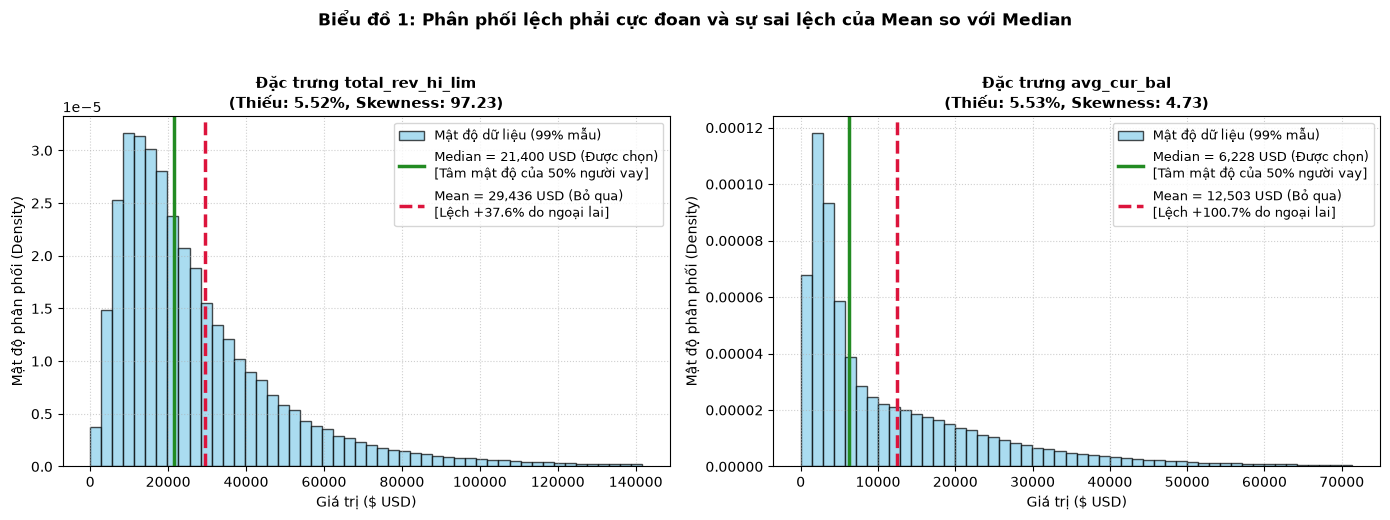

Đã lưu biểu đồ vào: ../artifacts/figures/02_bieu_do_1_skewness_mean_median.png


In [73]:
# Biểu đồ 1: Phân phối lệch phải và vị trí Mean vs Median
cols_median = ["total_rev_hi_lim", "avg_cur_bal"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, col in enumerate(cols_median):
    s = train[col].dropna()
    p99 = s.quantile(0.99)
    s_clipped = s[s <= p99]
    mean_val = float(s.mean())
    median_val = float(s.median())
    skew_val = float(s.skew())
    missing_rate = float(train[col].isna().mean())
    diff_pct = (mean_val - median_val) / median_val * 100
    
    ax = axes[i]
    ax.hist(s_clipped, bins=50, color='skyblue', edgecolor='black', alpha=0.7, density=True, label='Mật độ dữ liệu (99% mẫu)')
    ax.axvline(median_val, color='forestgreen', linestyle='-', linewidth=2.5, 
               label=f'Median = {median_val:,.0f} USD (Được chọn)\n[Tâm mật độ của 50% người vay]')
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2.5, 
               label=f'Mean = {mean_val:,.0f} USD (Bỏ qua)\n[Lệch +{diff_pct:.1f}% do ngoại lai]')
    
    ax.set_title(f"Đặc trưng {col}\n(Thiếu: {missing_rate:.2%}, Skewness: {skew_val:.2f})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Giá trị ($ USD)", fontsize=10)
    ax.set_ylabel("Mật độ phân phối (Density)", fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Biểu đồ 1: Phân phối lệch phải cực đoan và sự sai lệch của Mean so với Median", 
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
fig_1_path = FIG_DIR / "02_bieu_do_1_skewness_mean_median.png"
plt.savefig(fig_1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_1_path}")


**Biểu đồ 2.** So sánh trực quan tác động phân phối Trước và Sau khi điền: Dữ liệu gốc vs Điền Median vs Điền Mean.

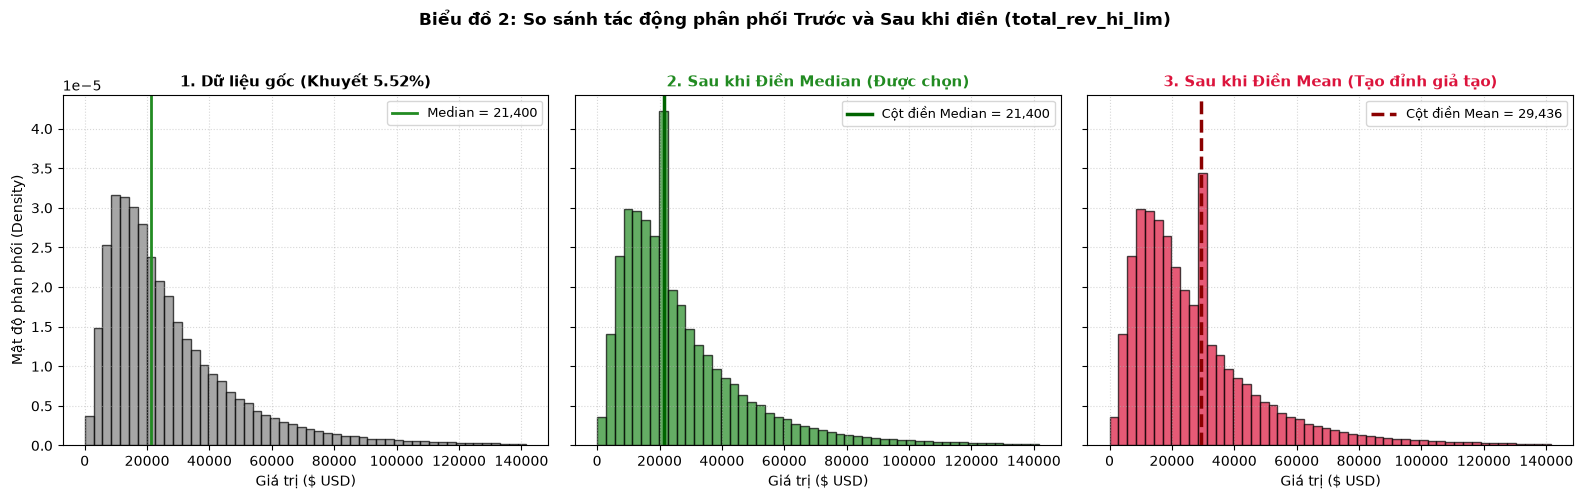

Đã lưu biểu đồ vào: ../artifacts/figures/02_bieu_do_2_tac_dong_fill_missing.png


In [74]:
# Biểu đồ 2: So sánh trực quan Trước và Sau khi điền: Gốc vs Điền Median vs Điền Mean
col_demo = "total_rev_hi_lim"
s_raw = train[col_demo].copy()
med_val = s_raw.median()
mean_val = s_raw.mean()
s_fill_median = s_raw.fillna(med_val)
s_fill_mean = s_raw.fillna(mean_val)

p99 = s_raw.quantile(0.99)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

# 1. Gốc (chưa điền)
axes[0].hist(s_raw[s_raw <= p99].dropna(), bins=50, color='gray', edgecolor='black', alpha=0.7, density=True)
axes[0].axvline(med_val, color='forestgreen', linestyle='-', lw=2, label=f'Median = {med_val:,.0f}')
axes[0].set_title(f"1. Dữ liệu gốc (Khuyết {s_raw.isna().mean():.2%})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Giá trị ($ USD)", fontsize=10)
axes[0].set_ylabel("Mật độ phân phối (Density)", fontsize=10)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Điền Median
axes[1].hist(s_fill_median[s_fill_median <= p99], bins=50, color='forestgreen', edgecolor='black', alpha=0.7, density=True)
axes[1].axvline(med_val, color='darkgreen', linestyle='-', lw=2.5, label=f'Cột điền Median = {med_val:,.0f}')
axes[1].set_title("2. Sau khi Điền Median (Được chọn)", fontsize=11, fontweight='bold', color='forestgreen')
axes[1].set_xlabel("Giá trị ($ USD)", fontsize=10)
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.5)

# 3. Điền Mean
axes[2].hist(s_fill_mean[s_fill_mean <= p99], bins=50, color='crimson', edgecolor='black', alpha=0.7, density=True)
axes[2].axvline(mean_val, color='darkred', linestyle='--', lw=2.5, label=f'Cột điền Mean = {mean_val:,.0f}')
axes[2].set_title("3. Sau khi Điền Mean (Tạo đỉnh giả tạo)", fontsize=11, fontweight='bold', color='crimson')
axes[2].set_xlabel("Giá trị ($ USD)", fontsize=10)
axes[2].legend(loc='upper right', fontsize=9)
axes[2].grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Biểu đồ 2: So sánh tác động phân phối Trước và Sau khi điền ({col_demo})", 
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
fig_2_path = FIG_DIR / "02_bieu_do_2_tac_dong_fill_missing.png"
plt.savefig(fig_2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_2_path}")


In [75]:
print("Nhận định thực nghiệm về chiến lược Điền Trung vị (Median Imputation):")
for col in cols_median:
    s = train[col].dropna()
    mean_v, med_v, sk_v = s.mean(), s.median(), s.skew()
    diff_p = (mean_v - med_v) / med_v * 100
    miss_pct = train[col].isna().mean() * 100
    print(f"- Cột '{col}' (thiếu {miss_pct:.2f}%): Median = {med_v:,.1f} USD vs Mean = {mean_v:,.1f} USD (chênh lệch +{diff_p:.1f}%, Skewness = {sk_v:.2f}).")
print("-> Kết luận: Điền bằng Trung vị tôn trọng vùng mật độ tập trung tự nhiên của 50% người vay, tránh tạo đỉnh giả tạo ở vùng thưa thớt như Mean.")


Nhận định thực nghiệm về chiến lược Điền Trung vị (Median Imputation):
- Cột 'total_rev_hi_lim' (thiếu 5.52%): Median = 21,400.0 USD vs Mean = 29,436.0 USD (chênh lệch +37.6%, Skewness = 97.23).
- Cột 'avg_cur_bal' (thiếu 5.53%): Median = 6,228.0 USD vs Mean = 12,502.7 USD (chênh lệch +100.7%, Skewness = 4.73).
-> Kết luận: Điền bằng Trung vị tôn trọng vùng mật độ tập trung tự nhiên của 50% người vay, tránh tạo đỉnh giả tạo ở vùng thưa thớt như Mean.


### 5.12.2 Lý giải thực nghiệm 2: Tại sao chọn Chuẩn hóa StandardScaler?

Bước tiếp theo trong khối xử lý cột số là `StandardScaler()` biến đổi mọi đặc trưng $x$ theo công thức:
$$z = \frac{x - \mu}{\sigma}$$
đưa phân phối về trung bình $\mu = 0$ và độ lệch chuẩn $\sigma = 1$. Kỹ thuật này bắt buộc vì 4 lý do thực tiễn:
1. **Khắc phục chênh lệch thang đo khổng lồ (Scale Disparity):**
   Trong bộ dữ liệu, các biến có đơn vị đo lường cực kỳ khác biệt:
   - Các biến quy mô tài chính lớn ($10^3$ đến $10^5$ USD): `tot_cur_bal` (~127,000 USD), `annual_inc` (~71,000 USD), `loan_amnt` (~14,000 USD).
   - Các biến tỷ lệ phần trăm ($10^1$ đến $10^2$): `dti` (~17.5%), `revol_util` (~52%).
   - Các biến đếm số lần quy mô nhỏ ($10^0$): `inq_last_6mths` (~0.7 lần), `delinq_2yrs` (~0.3 lần), `pub_rec` (~0.2 lần).
2. **Hỗ trợ tối ưu hóa Gradient Descent (Convergence Acceleration):**
   Đối với các mô hình tuyến tính như Hồi quy Logistic (Bước 6), mặt cầu hàm mất mát (loss surface) sẽ bị kéo giãn thành các đường elip cực kỳ dẹt nếu không scale dữ liệu. Việc chuẩn hóa giúp mặt hàm mất mát đối xứng hơn, thuật toán tối ưu hóa (như L-BFGS) hội tụ nhanh hơn nhiều lần và không bị phân kỳ.
3. **Đảm bảo tính công bằng của Phạt điều chuẩn ($L_2$ Regularization):**
   Trong hàm mất mát có thành phần phạt trọng số $\lambda \sum w_j^2$. Nếu không chuẩn hóa, các biến có thang đo hàng trăm nghìn USD (`annual_inc`) sẽ có trọng số $w$ cực kỳ nhỏ và gần như không bị phạt, trong khi các biến thang đo nhỏ (`delinq_2yrs`) sẽ có trọng số lớn và bị triệt tiêu oan uổng. Sau khi scale, tất cả trọng số đều chịu mức phạt công bằng như nhau.
4. **Khả năng giải thích và so sánh độ mạnh đặc trưng (Model Interpretability):**
   Khi tất cả các biến số đều có $\sigma = 1$, một độ lệch chuẩn tăng lên ở bất kỳ biến nào cũng tương đương nhau về mặt thống kê. Nhờ đó, ở Bước 6 ta có thể so sánh trực tiếp độ lớn tuyệt đối của các hệ số $|w_j|$ để xếp hạng các yếu tố rủi ro quan trọng nhất.


**Biểu đồ 3.** Chênh lệch thang đo gốc giữa các đặc trưng tài chính (trục logarit thể hiện khoảng cách đo lường hơn 100,000 lần).

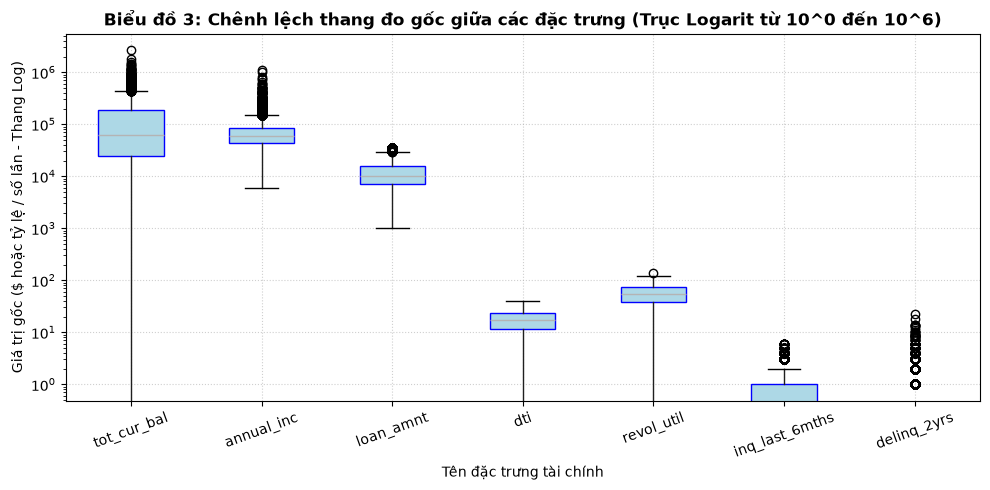

Đã lưu biểu đồ vào: ../artifacts/figures/02_bieu_do_3_chenh_lech_thang_do_goc.png


In [76]:
# Biểu đồ 3: Sự chênh lệch thang đo gốc cực lớn giữa các nhóm đặc trưng (Scale Disparity)
features_sample = ["tot_cur_bal", "annual_inc", "loan_amnt", "dti", "revol_util", "inq_last_6mths", "delinq_2yrs"]
sample_data = train[features_sample].dropna().sample(n=10000, random_state=SEED)

fig, ax = plt.subplots(figsize=(10, 5))
sample_data.boxplot(ax=ax, rot=20, patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))
ax.set_yscale('log')
ax.set_title("Biểu đồ 3: Chênh lệch thang đo gốc giữa các đặc trưng (Trục Logarit từ 10^0 đến 10^6)", fontsize=12, fontweight='bold')
ax.set_ylabel("Giá trị gốc ($ hoặc tỷ lệ / số lần - Thang Log)", fontsize=10)
ax.set_xlabel("Tên đặc trưng tài chính", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig_3_path = FIG_DIR / "02_bieu_do_3_chenh_lech_thang_do_goc.png"
plt.savefig(fig_3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_3_path}")


**Biểu đồ 4.** Phân phối chuẩn hóa sau StandardScaler (toàn bộ các biến quy về phân phối chuẩn tắc đồng nhất μ = 0, σ = 1).

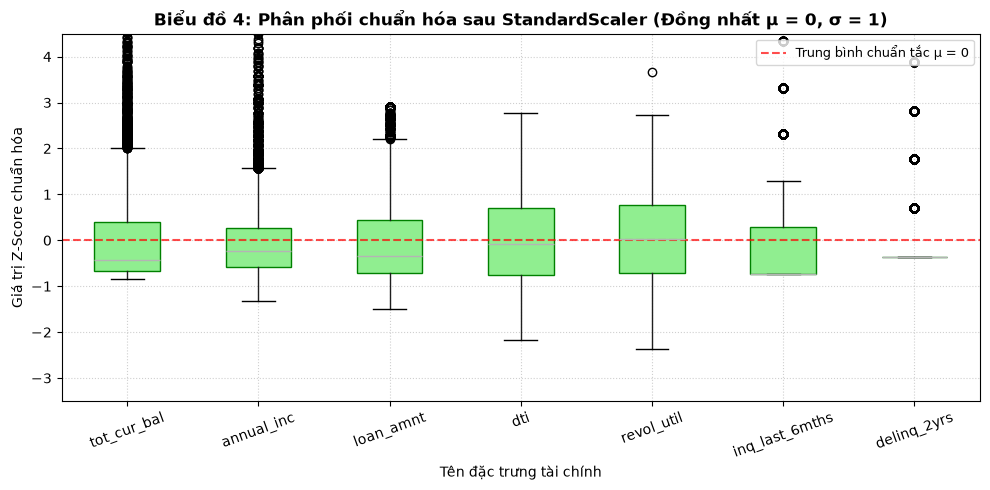

Đã lưu biểu đồ vào: ../artifacts/figures/02_bieu_do_4_chuan_hoa_standard_scaler.png


In [77]:
# Biểu đồ 4: Phân phối chuẩn hóa sau StandardScaler (Z-score: mu = 0, sigma = 1)
scaler_demo = StandardScaler()
scaled_data = pd.DataFrame(scaler_demo.fit_transform(sample_data), columns=features_sample)

fig, ax = plt.subplots(figsize=(10, 5))
scaled_data.boxplot(ax=ax, rot=20, patch_artist=True, boxprops=dict(facecolor='lightgreen', color='green'))
ax.set_ylim(-3.5, 4.5)
ax.axhline(0, color='red', linestyle='--', alpha=0.7, label='Trung bình chuẩn tắc μ = 0')
ax.set_title("Biểu đồ 4: Phân phối chuẩn hóa sau StandardScaler (Đồng nhất μ = 0, σ = 1)", fontsize=12, fontweight='bold')
ax.set_ylabel("Giá trị Z-Score chuẩn hóa", fontsize=10)
ax.set_xlabel("Tên đặc trưng tài chính", fontsize=10)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig_4_path = FIG_DIR / "02_bieu_do_4_chuan_hoa_standard_scaler.png"
plt.savefig(fig_4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_4_path}")


In [78]:
print("Nhận định thực nghiệm về chuẩn hóa StandardScaler:")
print(f"- Trước chuẩn hóa: Biên độ biến thiên từ {sample_data['delinq_2yrs'].mean():.2f} (delinq_2yrs) đến {sample_data['tot_cur_bal'].mean():,.0f} USD (tot_cur_bal) - chênh lệch hơn 100,000 lần.")
print(f"- Sau chuẩn hóa: Tất cả 7 biến đều có giá trị trung bình xấp xỉ 0 (max |μ| = {scaled_data.mean().abs().max():.2e}) và độ lệch chuẩn chính xác 1.0 (σ = {scaled_data.std().mean():.4f}).")
print("-> Toàn bộ các biến số bước vào mô hình với thang đo hoàn toàn bình đẳng, sẵn sàng cho việc tối ưu hóa và diễn giải hệ số.")


Nhận định thực nghiệm về chuẩn hóa StandardScaler:
- Trước chuẩn hóa: Biên độ biến thiên từ 0.34 (delinq_2yrs) đến 127,162 USD (tot_cur_bal) - chênh lệch hơn 100,000 lần.
- Sau chuẩn hóa: Tất cả 7 biến đều có giá trị trung bình xấp xỉ 0 (max |μ| = 5.07e-16) và độ lệch chuẩn chính xác 1.0 (σ = 1.0001).
-> Toàn bộ các biến số bước vào mô hình với thang đo hoàn toàn bình đẳng, sẵn sàng cho việc tối ưu hóa và diễn giải hệ số.


### 5.12.3 Cấu hình Pipeline hoàn chỉnh và Biến đổi dữ liệu
Pipeline ghép ba bước: làm sạch giá trị bất thường (`fix_invalid_values`), tạo feature mới (`add_features`), rồi điền thiếu / chuẩn hóa / one-hot (`make_preprocessor`). Ta `fit` chỉ trên `train`.


In [79]:
INPUT_COLUMNS = sorted((set(kept_candidates) | {"issue_date"}) - {"term"})
print("Số cột đầu vào thô của pipeline:", len(INPUT_COLUMNS))


Số cột đầu vào thô của pipeline: 58


In [80]:
def make_preprocessor(numeric_cols, categorical_cols):
    numeric_part = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    categorical_part = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("num", numeric_part, numeric_cols),
        ("cat", categorical_part, categorical_cols)
    ])

full_pipeline = Pipeline([
    ("clean", FunctionTransformer(fix_invalid_values)),
    ("features", FunctionTransformer(add_features)),
    ("prep", make_preprocessor(NUMERIC_FINAL, CATEGORICAL_FINAL)),
])


In [81]:
y_train, y_val, y_test = train["default"].to_numpy(), val["default"].to_numpy(), test["default"].to_numpy()
X_train_raw, X_val_raw, X_test_raw = train[INPUT_COLUMNS], val[INPUT_COLUMNS], test[INPUT_COLUMNS]
full_pipeline.fit(X_train_raw)
print("Đã fit pipeline trên train.")

Đã fit pipeline trên train.


In [82]:
X_train = full_pipeline.transform(X_train_raw)
X_val = full_pipeline.transform(X_val_raw)
X_test = full_pipeline.transform(X_test_raw)
print("Kích thước ma trận - train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

Kích thước ma trận - train: (408188, 153) | val: (92631, 153) | test: (88669, 153)


In [83]:
feature_names = list(full_pipeline.named_steps["prep"].get_feature_names_out())
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == len(feature_names)
print("Số cột sau biến đổi (gồm cả cột one-hot):", len(feature_names))
print("Có giá trị thiếu còn sót:", bool(np.isnan(X_train).any() or np.isnan(X_val).any() or np.isnan(X_test).any()))

Số cột sau biến đổi (gồm cả cột one-hot): 153
Có giá trị thiếu còn sót: False


**Bảng 17.** Thống kê của ma trận train sau biến đổi (cột số đã chuẩn hóa nên trung bình gần 0, độ lệch chuẩn gần 1).

In [84]:
numeric_block = pd.DataFrame(X_train[:, :len(NUMERIC_FINAL)], columns=NUMERIC_FINAL)
numeric_block.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
loan_amnt,0.000,1.000,-1.508,2.924
dti,-0.000,1.000,-2.166,2.788
delinq_2yrs,0.000,1.000,-0.361,33.490
inq_last_6mths,-0.000,1.000,-0.729,7.335
pub_rec,0.000,1.000,-0.337,107.487
revol_util,-0.000,1.000,-2.368,2.027
total_acc,-0.000,1.000,-1.946,11.776
collections_12_mths_ex_med,0.000,1.000,-0.097,156.596
tot_coll_amt,0.000,1.000,-0.015,633.799
total_rev_hi_lim,-0.000,1.000,-0.784,269.469


In [85]:
print(f"Trung bình các cột số train sau chuẩn hóa: lớn nhất theo trị tuyệt đối {numeric_block.mean().abs().max():.2e}.")
val_block = pd.DataFrame(X_val[:, :len(NUMERIC_FINAL)], columns=NUMERIC_FINAL)
print(f"Trung bình cột số ở val: lớn nhất theo trị tuyệt đối {val_block.mean().abs().max():.3f} "
      "(không về 0 vì val dùng trung bình/độ lệch chuẩn của train - đúng như thiết kế).")

Trung bình các cột số train sau chuẩn hóa: lớn nhất theo trị tuyệt đối 6.39e-16.
Trung bình cột số ở val: lớn nhất theo trị tuyệt đối 0.162 (không về 0 vì val dùng trung bình/độ lệch chuẩn của train - đúng như thiết kế).


**Kiểm tra pipeline cho kết quả giống hệt khi chạy lại** (không có yếu tố ngẫu nhiên).

In [86]:
pipeline_again = Pipeline([
    ("clean", FunctionTransformer(fix_invalid_values)),
    ("features", FunctionTransformer(add_features)),
    ("prep", make_preprocessor(NUMERIC_FINAL, CATEGORICAL_FINAL)),
]).fit(X_train_raw)
print("Fit lần hai cho ma trận val giống hệt lần một:", np.allclose(pipeline_again.transform(X_val_raw), X_val))

Fit lần hai cho ma trận val giống hệt lần một: True


## 5.13 Lưu pipeline và danh sách feature cho bước mô hình hóa

In [87]:
joblib.dump(full_pipeline, ART_DIR / "preprocess_pipeline.joblib")
feature_info = {"numeric": NUMERIC_FINAL, "categorical": CATEGORICAL_FINAL, "input_columns": INPUT_COLUMNS,
                "thresholds": {"DTI_MAX": DTI_MAX, "REVOL_UTIL_CAP": REVOL_UTIL_CAP, "LOAN_TO_INCOME_CAP": LOAN_TO_INCOME_CAP,
                               "MAX_MISSING": MAX_MISSING, "TOP_SHARE_CONSTANT": TOP_SHARE_CONSTANT,
                               "MAX_UNIQUE_CATEGORY": MAX_UNIQUE_CATEGORY, "CORR_THRESHOLD": CORR_THRESHOLD}}
(ART_DIR / "feature_info.json").write_text(json.dumps(feature_info, indent=2, ensure_ascii=False))
column_group.to_frame().join(data_dictionary[["meaning"]]).to_csv(ART_DIR / "column_groups.csv", encoding="utf-8-sig")
print("Đã lưu preprocess_pipeline.joblib, feature_info.json, column_groups.csv vào artifacts")

Đã lưu preprocess_pipeline.joblib, feature_info.json, column_groups.csv vào artifacts


## 5.14 Lưu ma trận dữ liệu chuẩn hóa cho bước mô hình hóa
Lưu ma trận đặc trưng `X` (float32) và nhãn `y` (int8) cho các tập train, val, test để nạp trực tiếp vào huấn luyện mô hình ở Notebook 3.

In [88]:
# Lưu ma trận X (float32) và nhãn y (int8)
splits = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
for split, (X_mat, y_arr) in splits.items():
    np.save(DATA_DIR / f"X_{split}.npy", X_mat.astype("float32"))
    np.save(DATA_DIR / f"y_{split}.npy", y_arr.astype("int8"))

# Lưu danh sách thông tin feature
feature_names_info = {
    "numeric": NUMERIC_FINAL,
    "categorical": CATEGORICAL_FINAL,
    "feature_names": feature_names,
    "n_features": len(feature_names),
}
(DATA_DIR / "feature_names.json").write_text(json.dumps(feature_names_info, indent=2, ensure_ascii=False))
print("Đã lưu X_train.npy, X_val.npy, X_test.npy, nhãn y và feature_names.json vào data/processed")

Đã lưu X_train.npy, X_val.npy, X_test.npy, nhãn y và feature_names.json vào data/processed


---
## 5.15 Bộ đặc trưng nâng cao: Mã hóa Weight of Evidence (WoE) cho Biến phân loại

Bên cạnh bộ đặc trưng cơ bản (153 cột qua One-Hot Encoding), trong nghiệp vụ xếp hạng tín dụng ngân hàng (Credit Scoring & Basel II), kỹ thuật **Weight of Evidence (WoE)** là chuẩn mực vàng để xử lý các biến phân loại:
$$\text{WoE}_j = \ln\left(\frac{\text{Tỷ lệ Nợ Xấu trong nhóm } j}{\text{Tỷ lệ Khách Tốt trong nhóm } j}\right) = \ln\left(\frac{\text{Bad}_j / \text{Total Bad}}{\text{Good}_j / \text{Total Good}}\right)$$

**Ưu điểm vượt trội của mã hóa WoE:**
1. **Khắc phục triệt để ma trận thưa (Sparsity Problem):** Thay vì tạo ra 108 cột nhị phân $0/1$ thưa thớt (khiến các thuật toán cây như Random Forest bị loãng khi chọn nhánh `max_features`), WoE biến đổi 5 biến phân loại thành **5 cột số liên tục** có tính đơn điệu cao.
2. **Tối ưu hóa cho Hồi quy Logistic:** Về mặt toán học, giá trị WoE tỷ lệ tuyến tính hoàn hảo với log-odds của xác suất vỡ nợ $\ln\left(\frac{P}{1-P}\right)$.
3. **Thu gọn không gian đặc trưng:** Giảm 67.3% kích thước đặc trưng (từ **153 cột xuống còn đúng 50 cột**: 45 cột số chuẩn hóa + 5 cột WoE), giúp tăng tốc độ huấn luyện gấp 3-4 lần.


In [89]:
def compute_woe_dict(df, col, target_col):
    total_good = (df[target_col] == 0).sum()
    total_bad = (df[target_col] == 1).sum()
    
    stats = df.groupby(col)[target_col].agg(
        good=lambda y: (y == 0).sum(),
        bad=lambda y: (y == 1).sum(),
    )
    # Laplace smoothing để tránh log(0) hoặc chia cho 0
    distr_good = (stats["good"] + 0.5) / (total_good + 1.0)
    distr_bad = (stats["bad"] + 0.5) / (total_bad + 1.0)
    
    # WoE = ln(Distr_Bad / Distr_Good): giá trị dương nghĩa là nhóm có rủi ro nợ xấu cao hơn trung bình
    woe = np.log(distr_bad / distr_good)
    return woe.to_dict()

# 1. Học bảng WoE strictly trên tập Train
woe_mappings = {}
train_woe_cols = np.zeros((len(train), len(CATEGORICAL_FINAL)), dtype=np.float32)
val_woe_cols = np.zeros((len(val), len(CATEGORICAL_FINAL)), dtype=np.float32)
test_woe_cols = np.zeros((len(test), len(CATEGORICAL_FINAL)), dtype=np.float32)

for i, col in enumerate(CATEGORICAL_FINAL):
    mapping = compute_woe_dict(train, col, "default")
    woe_mappings[col] = mapping
    train_woe_cols[:, i] = train[col].map(mapping).fillna(0.0).values
    val_woe_cols[:, i] = val[col].map(mapping).fillna(0.0).values
    test_woe_cols[:, i] = test[col].map(mapping).fillna(0.0).values
    print(f"- Cột '{col:20s}': {len(mapping):2d} nhóm, dải WoE từ {train_woe_cols[:, i].min():+.3f} đến {train_woe_cols[:, i].max():+.3f}")

# Lưu lại từ điển WoE
with open(ART_DIR / "woe_mappings.json", "w") as f:
    json.dump(woe_mappings, f, indent=2)
print("Đã lưu bảng ánh xạ WoE vào: artifacts/woe_mappings.json")


- Cột 'sub_grade           ': 35 nhóm, dải WoE từ -1.753 đến +1.459
- Cột 'home_ownership      ':  6 nhóm, dải WoE từ -0.228 đến +0.741
- Cột 'verification_status ':  3 nhóm, dải WoE từ -0.153 đến +0.120


- Cột 'purpose             ': 14 nhóm, dải WoE từ -0.207 đến +0.741


- Cột 'addr_state          ': 50 nhóm, dải WoE từ -0.476 đến +1.840
Đã lưu bảng ánh xạ WoE vào: artifacts/woe_mappings.json


In [90]:
# 2. Ghép 45 cột số (đã chuẩn hóa StandardScaler) với 5 cột WoE
# Lưu ý: X_train[:, :45] là 45 đặc trưng số sau khi đi qua prep pipeline
X_train_num = X_train[:, :len(NUMERIC_FINAL)]
X_val_num = X_val[:, :len(NUMERIC_FINAL)]
X_test_num = X_test[:, :len(NUMERIC_FINAL)]

X_train_woe = np.hstack([X_train_num, train_woe_cols]).astype("float32")
X_val_woe = np.hstack([X_val_num, val_woe_cols]).astype("float32")
X_test_woe = np.hstack([X_test_num, test_woe_cols]).astype("float32")

print("Kích thước bộ ma trận đặc trưng nâng cao (WoE):")
print(f"  - X_train_woe: {X_train_woe.shape} (giảm từ 153 cột xuống {X_train_woe.shape[1]} cột)")
print(f"  - X_val_woe:   {X_val_woe.shape}")
print(f"  - X_test_woe:  {X_test_woe.shape}")

# 3. Lưu trữ các ma trận WoE vào data/processed/
np.save(DATA_DIR / "X_train_woe.npy", X_train_woe)
np.save(DATA_DIR / "X_val_woe.npy", X_val_woe)
np.save(DATA_DIR / "X_test_woe.npy", X_test_woe)
print("Đã lưu thành công X_train_woe.npy, X_val_woe.npy, X_test_woe.npy vào data/processed/!")


Kích thước bộ ma trận đặc trưng nâng cao (WoE):
  - X_train_woe: (408188, 50) (giảm từ 153 cột xuống 50 cột)
  - X_val_woe:   (92631, 50)
  - X_test_woe:  (88669, 50)
Đã lưu thành công X_train_woe.npy, X_val_woe.npy, X_test_woe.npy vào data/processed/!


In [91]:
print("=" * 80)
print("TÓM TẮT BƯỚC 4 - 5 (TIỀN XỬ LÝ & KỸ THUẬT ĐẶC TRƯNG):")
print("=" * 80)
print(f"1. Không gian thô: {len(ALL_COLUMNS)} cột gốc -> {len(kept_candidates)} cột ứng viên -> {len(NUMERIC_FINAL)} cột số + {len(CATEGORICAL_FINAL)} phân loại.")
print(f"2. Bộ đặc trưng 1 (One-Hot tiêu chuẩn): 153 đặc trưng (train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}).")
print(f"3. Bộ đặc trưng 2 (Weight of Evidence nâng cao): 50 đặc trưng (train: {X_train_woe.shape}, val: {X_val_woe.shape}, test: {X_test_woe.shape}).")
print("4. Nguyên tắc rò rỉ: Toàn bộ thống kê (trung vị, chuẩn hóa, WoE mapping) chỉ học strictly trên train.")
print("=" * 80)


TÓM TẮT BƯỚC 4 - 5 (TIỀN XỬ LÝ & KỸ THUẬT ĐẶC TRƯNG):
1. Không gian thô: 151 cột gốc -> 57 cột ứng viên -> 45 cột số + 5 phân loại.
2. Bộ đặc trưng 1 (One-Hot tiêu chuẩn): 153 đặc trưng (train: (408188, 153), val: (92631, 153), test: (88669, 153)).
3. Bộ đặc trưng 2 (Weight of Evidence nâng cao): 50 đặc trưng (train: (408188, 50), val: (92631, 50), test: (88669, 50)).
4. Nguyên tắc rò rỉ: Toàn bộ thống kê (trung vị, chuẩn hóa, WoE mapping) chỉ học strictly trên train.
